# Image processing and face recognition

**Owner:** Tabitha (Image lead). Built from Tabitha's Colab work, cleaned up to run against the repo's code (`src/image_features.py`) and data.

The face model is the system's first gate: it decides **who** the user is, which picks their customer profile for the product model. The voice model then has to confirm it is the same member.

| Section | What it covers | Rubric criterion |
|---|---|---|
| 1 | Inventory and display of every photo | Image Quantity & Diversity |
| 2 | Face detection and cropping | Image Augmentation & Feature Extraction |
| 3 | Augmentation | Image Augmentation & Feature Extraction |
| 4 | Feature extraction to `image_features.csv` | Image Augmentation & Feature Extraction |
| 5 | Face model and evaluation | Model Implementation, Evaluation |
| 6 | Confidence threshold with outsiders | Multimodal Logic |
| 7 | Test it the way the app will use it | System Simulation |

The reusable code lives in `src/image_features.py`; this notebook calls it and explains each step. Rebuild the CSV and retrain the model from the repo root with `python src/image_features.py`.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from sklearn.metrics import ConfusionMatrixDisplay

import config
import image_features as fp   # crop_face, make_versions, get_numbers, cross_validate, recognise_face

FIG_DIR = config.FIGURES_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("Images folder:", config.IMAGES_DIR)

Images folder: C:\Users\tenio\multimodal-auth-recommender\data\images


## 1. Inventory: what photos do we have?

Each member took **neutral, smiling and surprised** photos, two takes of each, in two different places or lights. Files follow `<member>_<expression>[_2].jpg` in `data/images/<member>/`. Outsider photos (people outside the group) are in `data/unauthorized/images/` and are **never used for training**.

Phones store photos sideways and record the correct rotation in an EXIF "orientation" tag. `ImageOps.exif_transpose` applies that tag, so every photo is upright before we look for a face.

In [2]:
rows = []
for path in sorted(config.IMAGES_DIR.glob("*/*.jp*g")):
    img = Image.open(path)
    rows.append({"member": path.parent.name, "file": path.name, "expression": fp.expression_of(path),
                 "width": img.size[0], "height": img.size[1],
                 "exif_rotation": img.getexif().get(274, 1) not in (1, None)})
inventory = pd.DataFrame(rows)
display(inventory)
print(pd.crosstab(inventory["member"], inventory["expression"]).to_string())

,member,file,expression,width,height,exif_rotation
0,harmony,harmony_neutral.jpg,neutral,1920,2560,False
1,harmony,harmony_neutral_2.jpg,neutral,1920,2560,False
2,harmony,harmony_smiling.jpg,smiling,1920,2560,False
3,harmony,harmony_smiling_2.jpg,smiling,1920,2560,False
4,harmony,harmony_surprised.jpg,surprised,1920,2560,False
5,harmony,harmony_surprised_2.jpg,surprised,1920,2560,False
6,kethia,kethia_neutral.jpg,neutral,1280,960,False
7,kethia,kethia_neutral_2.jpg,neutral,1280,960,False
8,kethia,kethia_smiling.jpg,smiling,960,1280,False
9,kethia,kethia_smiling_2.jpg,smiling,1280,960,False


expression  neutral  smiling  surprised
member                                 
harmony           2        2          2
kethia            2        2          2
tabitha           2        2          2
towi              2        2          2


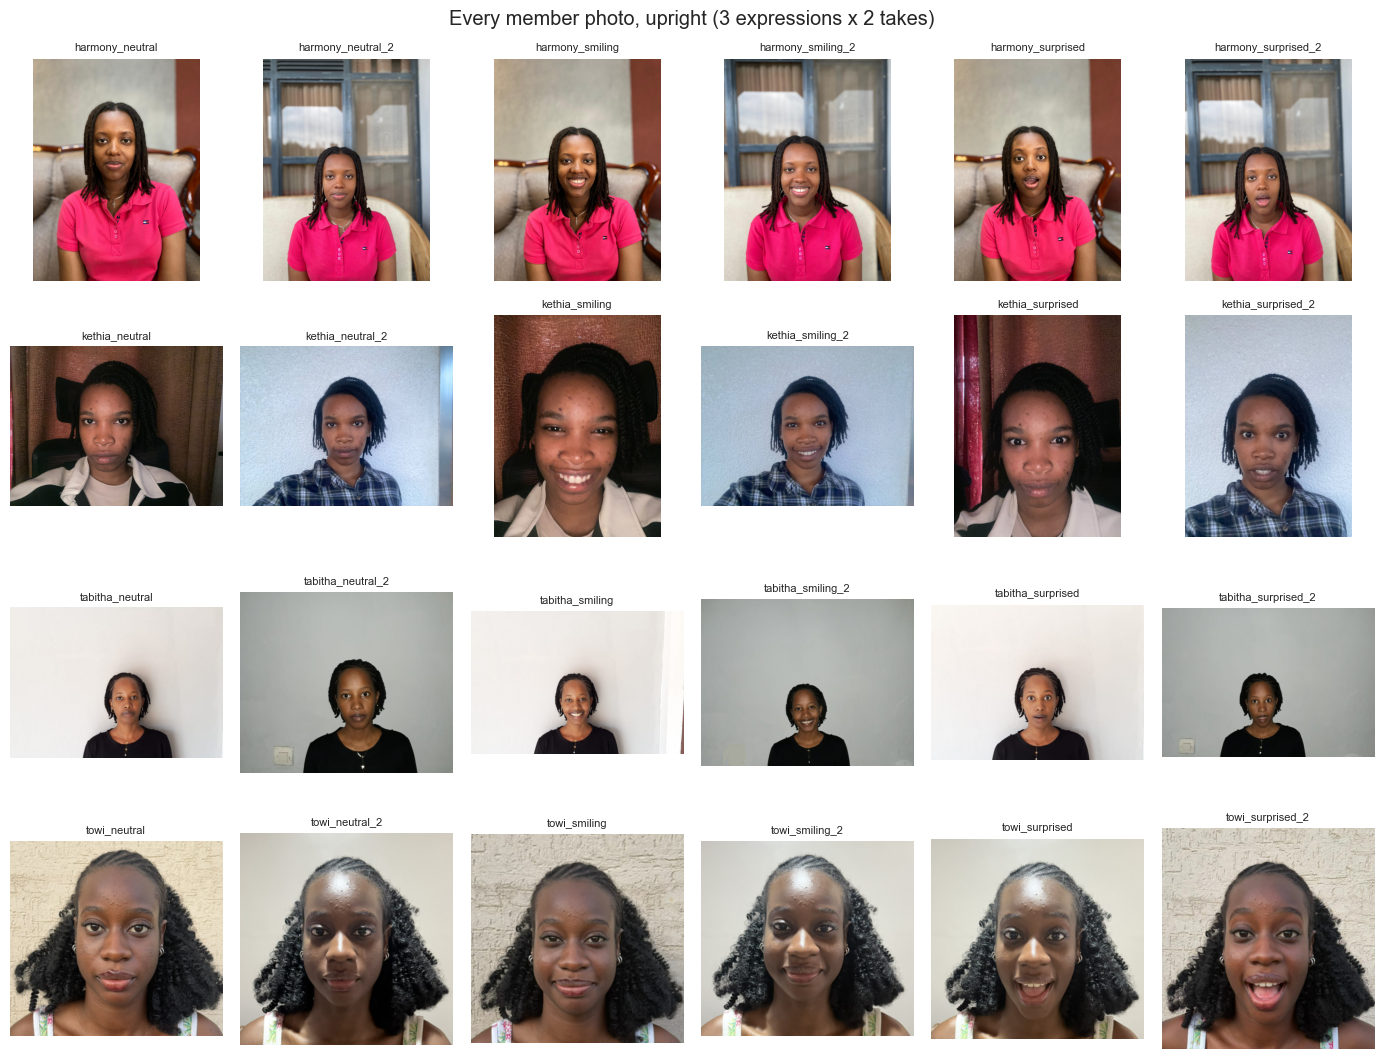

In [3]:
members = sorted(inventory["member"].unique())
fig, axes = plt.subplots(len(members), 6, figsize=(14, 2.7 * len(members)))
for r, m in enumerate(members):
    mine = inventory[inventory["member"] == m]["file"].tolist()
    for c in range(6):
        ax = axes[r, c]; ax.axis("off")
        if c < len(mine):
            ax.imshow(ImageOps.exif_transpose(Image.open(config.IMAGES_DIR / m / mine[c])))
            ax.set_title(mine[c].replace(".jpg", ""), fontsize=8)
fig.suptitle("Every member photo, upright (3 expressions x 2 takes)")
plt.tight_layout(); plt.savefig(FIG_DIR / "img_07_all_faces.png"); plt.show()

**Interpretation:** 24 photos in total: 6 per member, 2 of each expression. All files are JPG with the same naming pattern. The photos came from different phones, so sizes range from about 750 x 540 px (Tabitha) to 1920 x 2560 px (Harmony). None carry a rotation tag, but the upright step stays in the code as a safeguard for new phone photos. Each member's two takes are in different places or lighting, which gives the model some variety to learn from.

## 2. Face detection and cropping

`fp.crop_face()` uses OpenCV's ready-made Haar cascade face finder:

1. Convert to grayscale (the finder works on brightness patterns: eyes darker than cheeks, and so on).
2. Ignore anything smaller than 15% of the photo, so a face in a poster or a pattern in the background is skipped.
3. Try a strict search first, then softer ones only if nothing was found.
4. Keep the **biggest** face and add a 5% border, so the chin and hairline aren't cut off.

**Why crop at all?** Each of us took photos against our own backgrounds. Without cropping, the model could learn "white wall = Tabitha" instead of learning faces. Cropping also makes the face fill the 224 x 224 input, so detail isn't wasted on background.

The check below runs the cropper on **every** photo, to make sure no face was missed or cut wrongly.

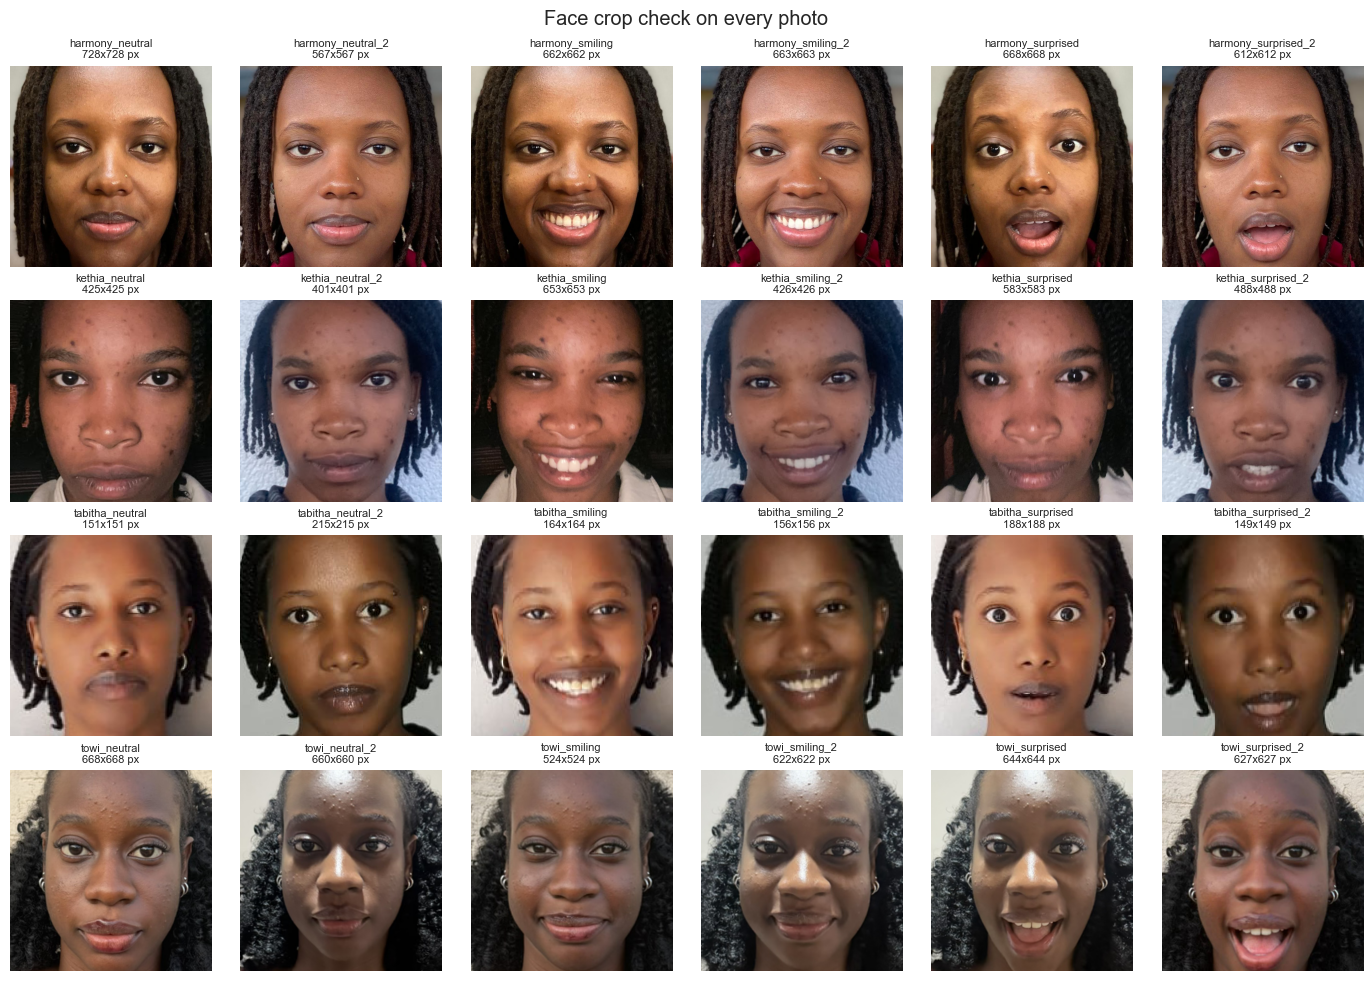

Photos where no face was found: none


In [4]:
fig, axes = plt.subplots(len(members), 6, figsize=(14, 2.5 * len(members)))
missed = []
for r, m in enumerate(members):
    mine = inventory[inventory["member"] == m]["file"].tolist()
    for c in range(6):
        ax = axes[r, c]; ax.axis("off")
        if c < len(mine):
            img = ImageOps.exif_transpose(Image.open(config.IMAGES_DIR / m / mine[c]))
            face = fp.crop_face(img)
            if face.size == img.size:
                missed.append(mine[c])
            ax.imshow(face); ax.set_title(f"{mine[c].replace('.jpg', '')}\n{face.size[0]}x{face.size[1]} px", fontsize=8)
fig.suptitle("Face crop check on every photo")
plt.tight_layout(); plt.savefig(FIG_DIR / "img_03_face_crops.png"); plt.show()
print("Photos where no face was found:", missed or "none")

**Interpretation:** A face was found in all 24 photos, and every crop is centred on the face with a small border, so nothing needed fixing by hand. Crop sizes reflect the original photos: Tabitha's faces are only 149 to 215 px across, so they are enlarged to 224 x 224 and come out slightly softer than the others. That is one reason it matters that the features (section 4) describe shapes rather than fine detail.

## 3. Augmentation

With 6 photos per person, the model needs to see variations it will meet in real use. `fp.make_versions()` makes 3 new versions of every cropped face:

| Version | What it simulates | Why it's safe |
|---|---|---|
| Flip (mirror) | A selfie camera that mirrors the image | Faces are close to symmetric, so it's still the same person |
| Rotate 15 degrees | A slightly tilted head | Small enough that the face stays recognisable |
| Grayscale | Different colour or lighting | Forces the model to rely on shape, not skin-tone lighting |

With the original that gives **4 rows per photo**.

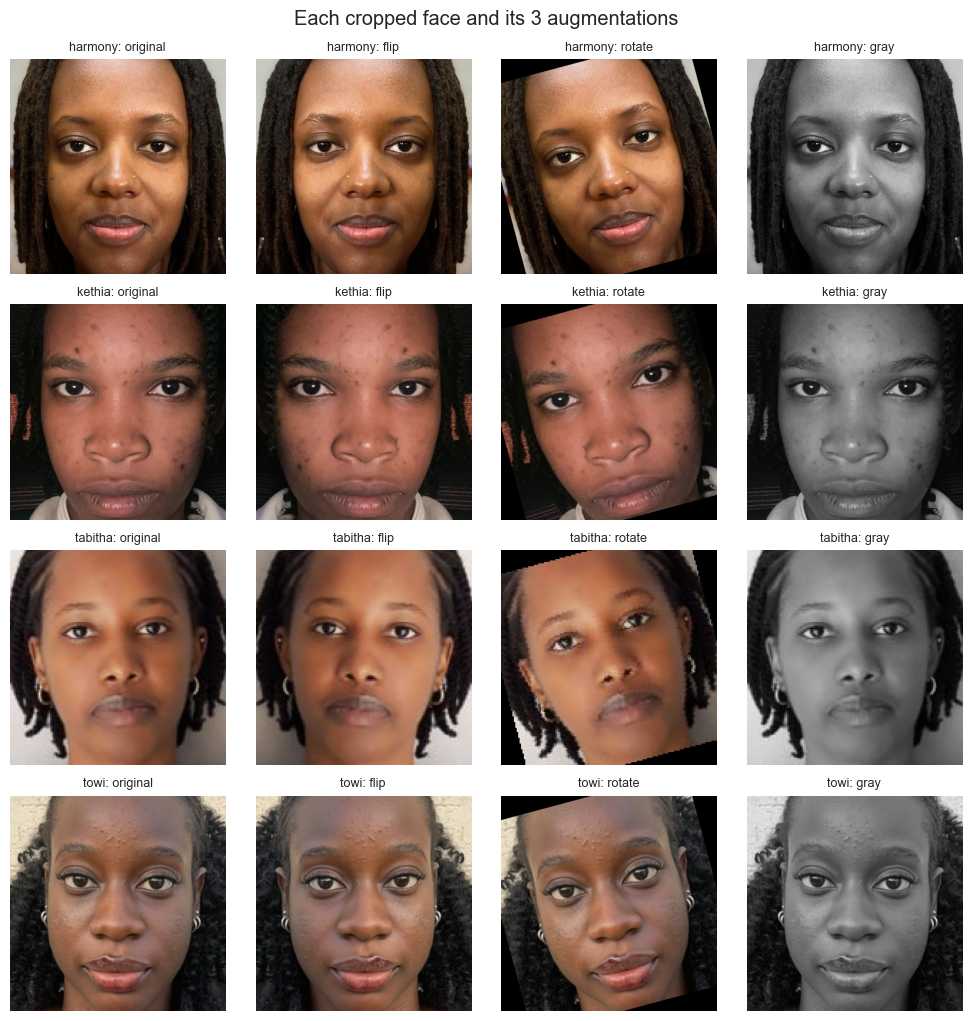

In [5]:
fig, axes = plt.subplots(len(members), 4, figsize=(10, 2.6 * len(members)))
for r, m in enumerate(members):
    first = sorted((config.IMAGES_DIR / m).glob("*.jp*g"))[0]
    face = fp.crop_face(ImageOps.exif_transpose(Image.open(first)))
    for c, (name, pic) in enumerate(fp.make_versions(face).items()):
        axes[r, c].imshow(pic); axes[r, c].axis("off")
        axes[r, c].set_title(f"{m}: {name}", fontsize=9)
fig.suptitle("Each cropped face and its 3 augmentations")
plt.tight_layout(); plt.savefig(FIG_DIR / "img_08_augmentations_per_member.png"); plt.show()

## 4. Feature extraction: turning a face into numbers

`fp.get_numbers()` passes each face through **MobileNetV2**, a network already trained on about 1.3 million ImageNet photos, with its last (classification) layer removed. What's left outputs **1,280 numbers** (an *embedding*) that describe the face: edges, textures, shapes of eyes, nose and mouth.

**Why this method?**
- **Not a CNN trained from scratch:** 24 photos is far too few. It would memorise them.
- **Not colour histograms:** they mostly measure lighting and background colour, which differ per person here for the wrong reasons.
- A pre-trained network already knows what faces are made of, so a simple model on top of its embedding can learn who is who from a few photos (*transfer learning*).

A good embedding puts photos of the same person close together. The heatmap checks that with **cosine similarity** (1 = pointing the same way, 0 = unrelated) between every pair of original photos.

(96, 1284) -> features\image_features.csv
augmentation  flip  gray  original  rotate
member                                    
harmony          6     6         6       6
kethia           6     6         6       6
tabitha          6     6         6       6
towi             6     6         6       6


,member,expression,augmentation,source_image,f_0,f_1,f_2,f_3
0,harmony,neutral,original,harmony_neutral.jpg,0.0,0.095922,0.012046,0.958283
1,harmony,neutral,flip,harmony_neutral.jpg,0.0,0.046172,0.016230,0.723369
2,harmony,neutral,rotate,harmony_neutral.jpg,0.0,0.333534,0.000000,1.784382
3,harmony,neutral,gray,harmony_neutral.jpg,0.0,0.089401,0.017000,1.211025


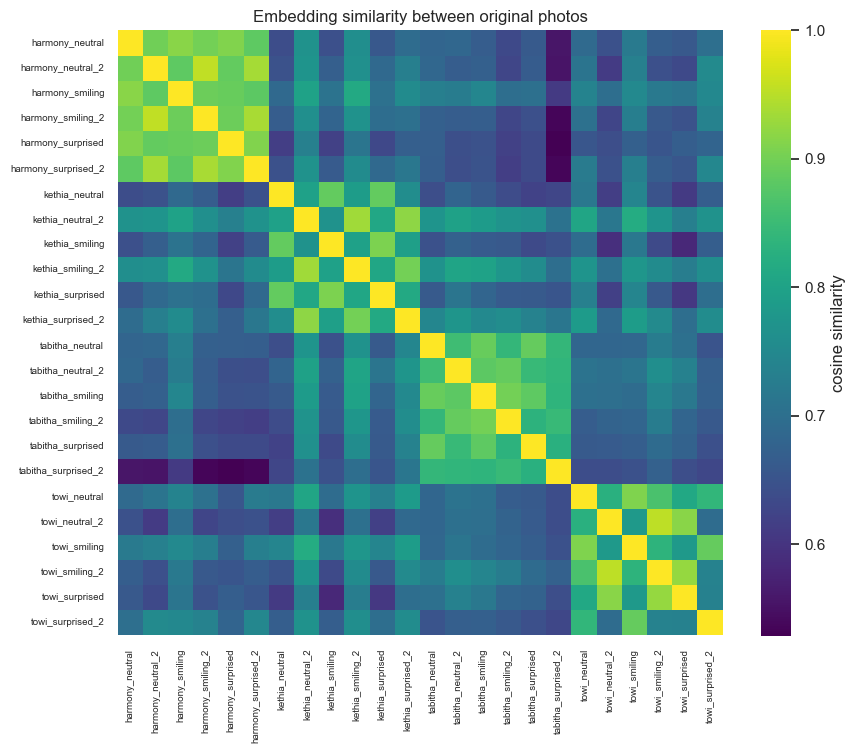

Average similarity, same person:      0.86
Average similarity, different people: 0.69


In [6]:
img_df = pd.read_csv(config.IMAGE_FEATURES_CSV)
feat_cols = [c for c in img_df.columns if c.startswith("f_")]
print(img_df.shape, "->", config.IMAGE_FEATURES_CSV.relative_to(ROOT))
print(img_df.groupby(["member", "augmentation"]).size().unstack().to_string())
display(img_df.iloc[:4, :8])

orig = img_df[img_df["augmentation"] == "original"].reset_index(drop=True)
X = orig[feat_cols].to_numpy()
Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
sim = Xn @ Xn.T
labels = orig["source_image"].str.replace(".jpg", "", regex=False)
plt.figure(figsize=(9, 7.5))
sns.heatmap(sim, xticklabels=labels, yticklabels=labels, cmap="viridis", square=True, cbar_kws={"label": "cosine similarity"})
plt.title("Embedding similarity between original photos")
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "img_04_embedding_similarity.png"); plt.show()

same = orig["member"].to_numpy()[:, None] == orig["member"].to_numpy()[None, :]
off_diag = ~np.eye(len(orig), dtype=bool)
print(f"Average similarity, same person:      {sim[same & off_diag].mean():.2f}")
print(f"Average similarity, different people: {sim[~same].mean():.2f}")

**Interpretation:** The four bright squares along the diagonal are the four people: photos of the same person are more alike (average 0.86) than photos of different people (0.69), before any model is trained. That is why a simple classifier is enough on top of this embedding. Look closer and each person's block splits into two smaller groups, one per photo session (for example Kethia's `_2` photos are closest to each other). So the embedding still picks up some of the session's lighting and background, even after cropping. It's the main reason the scores in section 5 may be optimistic.

## 5. Face model and evaluation

**Model:** standard scaling, then **logistic regression**. It's simple, works with few samples, and gives a probability for each member, which the app needs for its confidence threshold. Scaling puts all 1,280 numbers on the same footing.

**Fair evaluation: leave-one-photo-out.** An augmented copy is almost identical to its original. If a photo's flip were in training and the original in testing, the test would be too easy. So each round hides **one photo and all 3 of its copies**, trains on the rest, and predicts the hidden ones. Over 24 rounds every photo is tested once by a model that never saw it in any form.

**Metrics:** accuracy (how often the top guess is right), macro F1 (every member counts equally) and log loss (punishes confident wrong answers; random guessing among 4 members scores 1.39).

,accuracy,f1_macro,log_loss
all_rows,1.0,1.0,0.0057
originals_only,1.0,1.0,0.0046


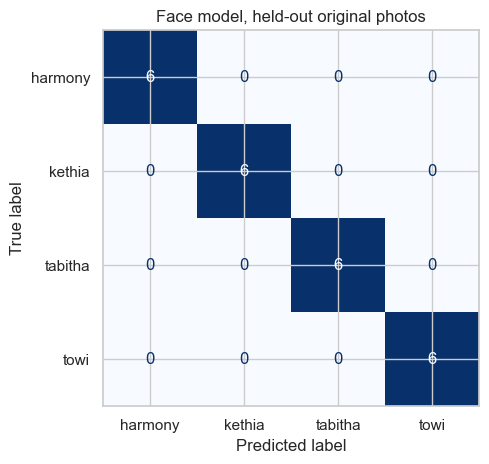

In [7]:
metrics, results = fp.cross_validate(img_df)
display(pd.DataFrame(metrics).T.round(4))

held = results[results["augmentation"] == "original"]
ConfusionMatrixDisplay.from_predictions(held["member"], held["predicted"], cmap="Blues", colorbar=False)
plt.title("Face model, held-out original photos")
plt.tight_layout(); plt.savefig(FIG_DIR / "img_05_face_confusion.png"); plt.show()

**Interpretation:** Every held-out photo was recognised correctly: accuracy 1.0, macro F1 1.0, and a log loss of 0.005, far below the 1.39 of random guessing, so the model is also confident when it is right. The augmented rows score the same as the originals, so flips, rotations and grayscale don't confuse it. We don't read this as a perfect face model: with 24 photos, and each person's photos taken in one or two sessions, the task is easier than recognising someone in a new place. Tabitha's first Colab run, which held out 2 random photos per person (8 photos), also scored 1.0. Leave-one-photo-out tests every photo, so it is the more thorough check.

## 6. Confidence threshold with outsiders

The model has only ever seen four people, so it **always** answers with one of them, even for a stranger: its probabilities must add up to 1. The app therefore needs a minimum confidence, below which the answer is "face not recognised".

We compare two groups the model never trained on:
- **Members, held out:** each original photo's confidence from the leave-one-photo-out rounds above.
- **Outsiders:** the photos in `data/unauthorized/images/`, scored by the final model.

The threshold should sit in the gap between them.

,file,model_says,confidence
0,outsider_towi_neutral.jpg,towi,0.857
1,outsider_towi_smiling.jpg,towi,0.686


Held-out members: min 0.964, median 0.999


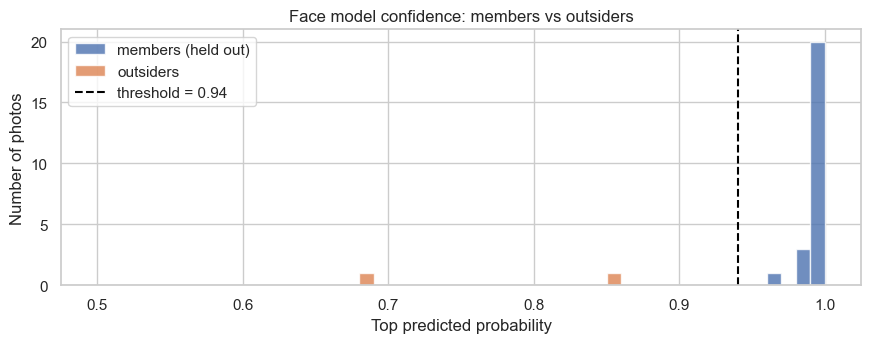

In [8]:
genuine = held.loc[held["predicted"] == held["member"], "confidence"]
outsiders = []
for p in sorted((config.UNAUTHORIZED_DIR / "images").glob("*.jp*g")):
    who, conf = fp.recognise_face(p)
    outsiders.append({"file": p.name, "model_says": who, "confidence": round(conf, 3)})
outsiders = pd.DataFrame(outsiders)
display(outsiders)
print(f"Held-out members: min {genuine.min():.3f}, median {genuine.median():.3f}")

plt.figure(figsize=(9, 3.6))
plt.hist(genuine, bins=np.arange(0.5, 1.0001, 0.01), alpha=0.8, label="members (held out)")
plt.hist(outsiders["confidence"], bins=np.arange(0.5, 1.0001, 0.01), alpha=0.8, label="outsiders")
plt.axvline(config.FACE_THRESHOLD, color="black", ls="--", label=f"threshold = {config.FACE_THRESHOLD}")
plt.xlabel("Top predicted probability"); plt.ylabel("Number of photos"); plt.legend()
plt.title("Face model confidence: members vs outsiders")
plt.tight_layout(); plt.savefig(FIG_DIR / "img_06_face_threshold.png"); plt.show()

**Interpretation:** Held-out member photos score between 0.964 and 1.000; the lowest is Towi's newest photo (`towi_surprised_2`), the least like her others. The outsider photos score 0.686 and 0.857, and the model's best guess for this stranger is Towi in both, so without a threshold a lookalike would be let in as Towi. Any threshold between 0.857 and 0.964 separates the two groups. We use **0.94**: it leaves a margin of 0.08 above the outsider and still accepts every member photo, and it leans towards rejecting, because letting a stranger in is a worse mistake than asking a member to try again. With only two outsider photos from one person, this gap is a small sample: more outsiders would make the threshold more reliable.

## 7. Test it the way the app will

`fp.recognise_face(path)` is what `src/app.py` calls first. It opens the photo, crops the face, computes the embedding and returns `(member, confidence)`. The app then applies `config.FACE_THRESHOLD`.

In [9]:
checks = [config.IMAGES_DIR / "towi" / "towi_neutral.jpg",
          config.IMAGES_DIR / "kethia" / "kethia_smiling_2.jpg",
          *sorted((config.UNAUTHORIZED_DIR / "images").glob("*.jp*g"))]
for p in checks:
    who, conf = fp.recognise_face(p)
    decision = "RECOGNISED" if conf >= config.FACE_THRESHOLD else "NOT RECOGNISED"
    print(f"{p.name:30} -> {who:8} {conf:.3f}  {decision}")

towi_neutral.jpg               -> towi     0.999  RECOGNISED
kethia_smiling_2.jpg           -> kethia   0.998  RECOGNISED


outsider_towi_neutral.jpg      -> towi     0.857  NOT RECOGNISED
outsider_towi_smiling.jpg      -> towi     0.686  NOT RECOGNISED


**Note:** the member photos above were also used to train the final model, so passing them only shows the plumbing works. The real measure is the held-out result in section 5.

## Summary

- **Data:** 24 photos, 6 per member, 3 expressions each, consistent names, all faces found.
- **Augmentation:** flip, 15 degree rotation, grayscale, so 96 rows in `features/image_features.csv` (member, expression, augmentation, source_image, and 1,280 embedding numbers).
- **Features:** MobileNetV2 embeddings (transfer learning), which already group photos by person (0.86 vs 0.69 similarity).
- **Model:** scaling + logistic regression; leave-one-photo-out accuracy 1.0, macro F1 1.0, log loss 0.005.
- **Threshold:** 0.94, between outsiders (0.69, 0.86) and held-out members (0.964 or more).
- **Limits:** few photos and sessions per person, one outsider. More photos in new places, and more outsiders, are the next step.